In [1]:
## Python Stuff
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

os.environ.get("ROOTSYS")

"""
run with:
see code1analysis/ana1_Cs_bkgs_v1.ipynb for instructions on running jlab
"""

'\nrun with:\nsee code1analysis/ana1_Cs_bkgs_v1.ipynb for instructions on running jlab\n'

In [2]:
# 1. have to also handle uncertainties on bins (from ROOT bkg subtraction) 
#   and how do i handle this throughout (for ks test, etc)

# 2. is my zero PE bin in data okay?

# 3. to keep the rate thing consistent, I think I need one global variable 
#   to scale all of the simulation data.

# 4. ks test is sensitive to the far range. Do I do log-bin spacing?

# to do rn:
# 1. 

# ? is commong scaling to different heights correct?

# change anaStructs object so that i don't have to distinguish between 
# raw or rate data. just make two histograms for each object

## Framework items ##
# 1. somehow group all 'heights' and do scaling minimization

# 2. group the correct mac runs together (heights vs light yields)

# 3. do global minimization

# 4. sum reduced chi2 as 'weighted sum'

# change FullMCRun.setup_forComparison to setup for plotting, then have something else to 
# the range of the bins used for KS test

# fix bkg subtraction. do bkg_rate * runTime of data

# I need to combine both classes/helpers (on gitlab it will become an issue)

# some bins are negative after bkg subtraction --> make them zero

# do i add the chi2 from each histogram

# markov chain and run the MC 'live'


In [3]:
## Overvoltage at 48 V is 4.5V (from noise_extraction.ipynb)
pCA = 0.35 # first VUV4 paper, 163K

# from second Giacomo nEXO paper. Our SiPM is VUV4-Q-50
pCA = 0.17

In [4]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(300)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
ROOT.enableJSVis()
# ROOT.disableJSVis()

Welcome to JupyROOT 6.27/01


In [5]:
## loading tools for data
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")

## Atown's stuff
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

sys.path.append(os.environ.get("CF4G4"))
from Batch.helpers.FileGetters import *
from Batch.helpers.G4_runClasses import *
from Batch.helpers.G4_macHelpers import *

print(sys.path)

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/helpers']


In [6]:
## ------------- User Inputs ------------- ##
## USER INPUTS (kinda bad ngl) ##
NCHAN = 3
VERBOSE = False
ASK_MATPLOT = True
DO2D = False

#QVAR_USE = "qRCFlat"
# QVAR_USE = "qRCFixed"
QVAR_USE = "qFlat"
# QVAR_USE = "qFixed"
PECUTVALUE = 0.5

## Paths to files, runLists
defPath = str(os.environ["CF4HOME"])+"/procData/" # where to get everything
bkgRunPath = "runLists/analysis1/bkgLists/"       # bkg run list files

## -------- physics and bkg runs -------- ##
# runID_co_bare_heights = [202203031411, 202203031118, 202203031135, 202203041257, 202203031512]
# cs_bare_heights = [28, 30.5, 30.5, 30.5, 33]
runID_co_bare_heights = [202203031411, 202203031135, 202203031512]
co_bare_heights = [28., 30.5, 33.]

runID_co_LP_heights = [202204131513,	202204131317,	202204131122]
co_LP_heights = [26, 28.5,	30.5]

physicsList = runID_co_bare_heights + runID_co_LP_heights

# bkg runs
bkgList_0303 = np.loadtxt(defPath + bkgRunPath+ "date_0303-48V.txt", dtype=int).tolist()
bkgList_0413 = np.loadtxt(defPath + bkgRunPath+ "date_0413-48V.txt", dtype=int).tolist()
# bkgList_1412 = np.loadtxt(defPath + bkgRunPath+ "date_0412-48V.txt", dtype=int).tolist()

# final inputs into code
allBkgs = bkgList_0303 + bkgList_0413
allRuns = allBkgs + physicsList

In [7]:
## Get all data RC objects, build needed SPE histograms ##
ROOT.gErrorIgnoreLevel = ROOT.kError
rcList = [] ## everything from here
fList = []

speList = []
chi2list = []

# loading data and SPE analysis
# everything is in rcList
for run in allRuns:
  f = ROOT.TFile(defPath + "analysis1/npv1_" + str(run) + ".root", "READ") #file opens
  fList.append(f) # NEED THIS to keep ttrees persistent (all reference in Python)

  tt = f.Get("tt")
  rcObj = RunClass(run, tt)

  rcObj.assign_height(runID_co_bare_heights, co_bare_heights)
  rcObj.assign_height(runID_co_LP_heights, co_LP_heights)

  rcObj.computeSPE(width = 15, verbose=VERBOSE, varname=QVAR_USE, channels = [i for i in range(NCHAN)])
  rcList.append(rcObj)

  for chan in rcObj.mChannels:
    # print(chan.mSpe.chi2)
    speList.append(chan.mSpe.spe)
    chi2list.append(chan.mSpe.chi2)
ROOT.gErrorIgnoreLevel = ROOT.kUnset
print("Done Calculating SPE")

Done Calculating SPE


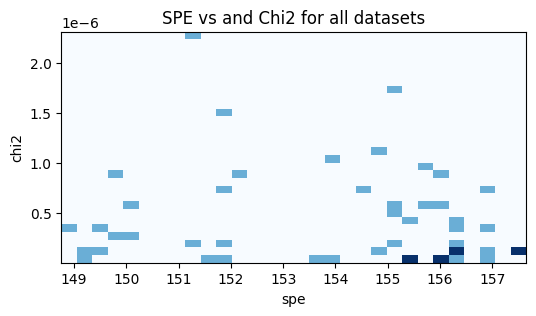

In [8]:
## checking spe and chi2 values
plt.figure(figsize=(6, 3))
plt.hist2d(speList, chi2list, bins=30, cmap='Blues')
plt.title("SPE vs and Chi2 for all datasets")
plt.xlabel("spe")
plt.ylabel("chi2")
plt.show()

In [9]:
#### Sorting RC objects ####
rcl_Bkg_0303 = SORTING.pickListOfRC(bkgList_0303, rcList) # get all RC background objects
rcl_co_bare_heights = SORTING.pickListOfRC(runID_co_bare_heights, rcList)

rcl_Bkg_0413 = SORTING.pickListOfRC(bkgList_0413, rcList) # get all RC background objects
rcl_co_lp_heights = SORTING.pickListOfRC(runID_co_LP_heights, rcList)

######## Building Full Spectra ########
binLow = 0.5
binHigh = 100.5
Nbins = 100.
binWidth = (binHigh - binLow) / Nbins
hReference = TH1F("hReference", "hReference", int(Nbins), binLow, binHigh) # histogram that everything is built off
hReference.Sumw2(True)

# building all SPE spectra
for rc in rcList:
  rc.BuildSpectrum(hReference, QVAR_USE, PECUTVALUE, rate = True)

# building averaged bkg spectra
hNPE_bkg_0303 = hReference.Clone("hNPE_bkg_0303") # histogram
GB.build_bkgHistogramFast(rcl_Bkg_0303, QVAR_USE, hNPE_bkg_0303, PECUTVALUE) # this calls build_SPEFixedHistogram iteratively, does rate calculation...

hNPE_bkg_0413 = hReference.Clone("hNPE_bkg_0413") # histogram
GB.build_bkgHistogramFast(rcl_Bkg_0413, QVAR_USE, hNPE_bkg_0413, PECUTVALUE) # this calls build_SPEFixedHistogram iteratively, does rate calculation...

In [10]:
## plotting reference (bkg) figures 
c0 = TCanvas()
c0.SetLogy()

hReference.GetXaxis().SetRangeUser(0, 20)
hReference.Draw("hist")
hReference.SetTitle("0303 bkg data")

for rc in rcl_Bkg_0303:
  h = rc.GetSpectrum()
  h.SetLineColor(rcl_Bkg_0303.index(rc)+1)
  h.SetLineWidth(3)

  h.Draw("hist same E")
c0.Update()
c0.Draw()

c1 = TCanvas()
c1.SetLogy()

hReference2 = hReference.Clone("hReference2")
hReference2.Draw("hist")
hReference2.SetTitle("0413 bkg data")
hReference2.GetYaxis().SetRangeUser(0.001, 100)

for rc in rcl_Bkg_0413:
  h = rc.GetSpectrum()
  h.SetLineColor(rcl_Bkg_0413.index(rc)+1)
  h.SetLineWidth(2)

  h.Draw("hist same E")

c1.Update()
c1.Draw()

In [11]:
## Get and build the bkg corrected spectra
print("Bare:")
for rc in rcl_co_bare_heights:
  rc.FindClosestRC(rcl_Bkg_0303)
  rc.BuildCorrSpectrum()
  rc.setup_forComparison()
  print(rc.mHeight)

print("\n Filtered")
for rc in rcl_co_lp_heights:
  rc.FindClosestRC(rcl_Bkg_0413)
  rc.BuildCorrSpectrum()
  rc.setup_forComparison()
  print(rc.mHeight)


Bare:
28.0
30.5
33.0

 Filtered
26
28.5
30.5


In [12]:
## looking for specific RC objects (data runs)
rcBare_0cm = SORTING.findRCbyHeight(33., rcl_co_bare_heights)
rcBare_1d5cm = SORTING.findRCbyHeight(30.5, rcl_co_bare_heights)
rcBare_4cm = SORTING.findRCbyHeight(28., rcl_co_bare_heights)
# rcBare_55cm = SORTING.findRCbyHeight(26.5, rcl_co_bare_heights)

# rcLP_0cm = SORTING.findRCbyHeight(32, rcl_co_lp_heights)
rcLP_1d5cm = SORTING.findRCbyHeight(30.5, rcl_co_lp_heights)
rcLP_3d5cm = SORTING.findRCbyHeight(28.5, rcl_co_lp_heights)
rcLP_6cm = SORTING.findRCbyHeight(26, rcl_co_lp_heights)

# rcBare_4cm.tt.Show(0)

rcBare_4cm.print()
rcLP_3d5cm.print()


runID: 202203031411
Nevents: 50058.00,   time: 17.68 min
average Rate: 47.19 Hz
height = 28.00
chID:0: spe = 151.51 +/- 0.27     maxChi2 = 0.00
chID:1: spe = 155.02 +/- 0.36     maxChi2 = 0.00
chID:2: spe = 156.15 +/- 0.73     maxChi2 = 0.00

runID: 202204131317
Nevents: 111250.00,   time: 41.72 min
average Rate: 44.44 Hz
height = 28.50
chID:0: spe = 149.65 +/- 0.19     maxChi2 = 0.00
chID:1: spe = 155.46 +/- 0.34     maxChi2 = 0.00
chID:2: spe = 156.97 +/- 0.29     maxChi2 = 0.00


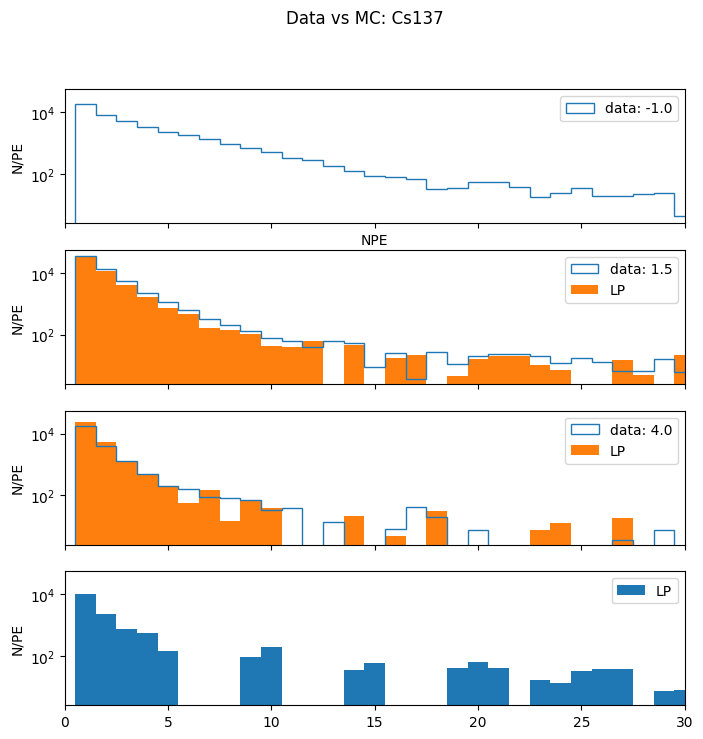

In [13]:
fig, axs = plt.subplots(4, 1, figsize = (8, 8), sharey=True, sharex=True)
ax1 = axs[0]
ax2 = axs[1]
ax3 = axs[2]
ax4 = axs[3]

hScale = 32.
mcScale = 0.3119 # from a fit, adding total chi2

# 32 = 0 cm run
# areaData = sum(rcBare_0cm.mBin_rawCounts[binStart:binEnd])
ax1.hist(x = rcBare_0cm.mBinX, bins = rcBare_0cm.mBin_edges, weights = rcBare_0cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale - rcBare_0cm.mHeight))
# ax1.hist(x = mc_0cm.mBinX, bins = mc_0cm.mBin_Edges, weights=mc_0cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_0cm.mRunPars.gammaHeight))
# ax1.hist(x = rcLP_0cm.mBinX, bins = rcLP_0cm.mBin_edges, weights = rcLP_0cm.mBin_rawCounts, label = "LP filter")

# 30.5 = 1.5 cm run
ax2.hist(x = rcBare_1d5cm.mBinX, bins = rcBare_1d5cm.mBin_edges, weights = rcBare_1d5cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale - rcBare_1d5cm.mHeight))
# ax2.hist(x = mc_1d5cm.mBinX, bins = mc_1d5cm.mBin_Edges, weights=mc_1d5cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_1d5cm.mRunPars.gammaHeight))
ax2.hist(x = rcLP_1d5cm.mBinX, bins = rcLP_1d5cm.mBin_edges, weights = rcLP_1d5cm.mBin_rawCounts, label = "LP")

# 34  =  4cm 
ax3.hist(x = rcBare_4cm.mBinX, bins = rcBare_4cm.mBin_edges, weights = rcBare_4cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale -rcBare_4cm.mHeight))
# ax3.hist(x = mc_4cm.mBinX, bins = mc_4cm.mBin_Edges, weights=mc_4cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_4cm.mRunPars.gammaHeight))
ax3.hist(x = rcLP_3d5cm.mBinX, bins = rcLP_3d5cm.mBin_edges, weights = rcLP_3d5cm.mBin_rawCounts, label = "LP")

# 26.5 = 5.5cm
# ax4.hist(x = rcBare_55cm.mBinX, bins = rcBare_55cm.mBin_edges, weights = rcBare_55cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale - rcBare_55cm.mHeight))
# ax4.hist(x = mc_55cm.mBinX, bins = mc_55cm.mBin_Edges, weights=mc_55cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_55cm.mRunPars.gammaHeight))
ax4.hist(x = rcLP_6cm.mBinX, bins = rcLP_6cm.mBin_edges, weights = rcLP_6cm.mBin_rawCounts, label = "LP")
# plt.hist(x = mcEdges[:-1], bins = mcEdges, weights=mcCounts, label = "MC")

for ax in axs.flat:
  ax.set_ylabel("N/PE")
  ax.set_xlim(0, 30)
  ax.legend()

ax1.set_xlabel("NPE")
fig.suptitle("Data vs MC: Cs137")
ax1.set_yscale("log")
# ax1.set_ylim(0, 20)
# ax1.set_xlim(0, 30)

# plt.legend()
plt.show()
# print(rcBare_0cm.mBin_edges[0])

# mcEdges[0:4]